# 04 · `to_allen.py`: NextBrain → Allen ontology

`to_allen(nextbrain, ontology="gyral", compat16bits=False, save=False)` turns
NextBrain IDs into Allen IDs.

* **Subcortical labels (< 1000)** are matched **by name**. Both names are
  normalised (`normalize_name`) and compared with every node of the Allen tree.
* **Cortical DK labels (2000–2035)** have no Allen equivalent. A
  hand-written table maps them to one of three choices (`CortexOntology`):

| value | aliases | DK labels become |
|---|---|---|
| `"gyral"` (default) | `gyr` | best-guess Allen **gyral** nodes (superior frontal gyrus, ...) |
| `"developmental"` | `dev` | coarse Allen **neocortex lobes** (frontal/parietal/... neocortex) |
| `"desikan-killiany"` | `dk` | **unchanged** (2000–2035; no Allen ID uses this range) |

In [1]:
import sys, os
from pathlib import Path
sys.path.insert(0, ".")          # nb_helpers.py lives next to the notebooks
WORK = Path("_work/04"); WORK.mkdir(parents=True, exist_ok=True)   # scratch outputs of this notebook

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import nb_helpers as H
pd.set_option("display.max_rows", 60, "display.max_colwidth", 70)

In [2]:
from nextbrain_utils import to_allen as TA
from nextbrain_utils.io import load_lut, load_ontology
from nextbrain_utils.lut import allen_lut
nxb_lut, ont = load_lut(), load_ontology()

print(list(TA.CortexOntology))
print(TA._ensure_cortex_onto("gyr"), TA._ensure_cortex_onto("dev"), TA._ensure_cortex_onto("desikan-killiany"))

[<CortexOntology.dev: 'developmental'>, <CortexOntology.gyr: 'gyral'>, <CortexOntology.dk: 'desikan-killiany'>]
gyral developmental desikan-killiany


## Name normalisation

`normalize_name` lowercases, strips a leading `ctx-` and then `lh-`/`rh-`,
removes commas, turns `-`/`_` into spaces and collapses repeated spaces. This
lets NextBrain's `substantia_nigra__compact_part` match Allen's
`substantia nigra, compact part`.

In [3]:
for s in ["substantia_nigra__compact_part", "substantia nigra, compact part",
          "ctx-rh-superiorfrontal", "ctx-superiorfrontal", "Left-Putamen"]:
    print(f"{s!r:38s} -> {TA.normalize_name(s)!r}")

'substantia_nigra__compact_part'       -> 'substantia nigra compact part'
'substantia nigra, compact part'       -> 'substantia nigra compact part'
'ctx-rh-superiorfrontal'               -> 'superiorfrontal'
'ctx-superiorfrontal'                  -> 'superiorfrontal'
'Left-Putamen'                         -> 'left putamen'


Note: `normalize_name` does **not** strip a `left`/`right` word (that line is
commented out), so `Left-Putamen` keeps `left`.

## ⚠️ Bug 1: the default ontology crashes

To look up the cortex table, `get_nextbrain2allen_map` uses `key[7:]`, which
assumes cortical names look like `ctx-rh-<name>`. The current `NextBrainLUT.txt`
uses `ctx-<name>`, so `"ctx-unknown"[7:] == "nown"`:

In [4]:
for onto in ["gyral", "developmental", "desikan-killiany"]:
    try:
        TA.get_nextbrain2allen_map(onto)
        print(f"{onto:17s} OK")
    except KeyError as e:
        print(f"{onto:17s} KeyError {e}")

gyral             KeyError 'nown'
developmental     KeyError 'nown'
desikan-killiany  OK


The proper fix is one line in `to_allen.py`: strip the prefix with
`normalize_name` (which already handles both forms), e.g.
`nextbrain_norm[key] = cortex_map[normalize_name(key)]`. To keep the library
untouched, this series uses the context manager `H.patched_nextbrain_lut()`
instead. It makes `to_allen` see `ctx-rh-<name>` again.

In [5]:
with H.patched_nextbrain_lut():
    maps = {o: TA.get_nextbrain2allen_map(o) for o in ["gyral", "developmental", "desikan-killiany"]}
print({k: v.shape for k, v in maps.items()})

{'gyral': (2036,), 'developmental': (2036,), 'desikan-killiany': (2036,)}


## Inside `get_nextbrain2allen_map`

1. `nextbrain2allen = np.arange(max_id + 1)`: identity, dtype `int32`.
2. Build `{original NextBrain name: normalised name}`. For cortex, replace the
   normalised name with the target name from the hand table
   (`_fscortex_to_allen_gyral` or `_fscortex_to_allen_dev`).
3. Walk the Allen tree recursively. Whenever a node's normalised name equals a
   NextBrain normalised name, set `nextbrain2allen[nb_id] = node["id"]`.
   (If several nodes had the same normalised name, the last one visited would
   win.)

Let us look at the resulting table:

In [6]:
allen_by_id = {}
def _w(n):
    allen_by_id[n["id"]] = n["name"]; [_w(c) for c in n.get("children", [])]
_w(ont)

m = maps["gyral"]
tab = pd.DataFrame({"nb_id": nxb_lut.labels, "nb_name": nxb_lut.names})
tab["allen_id"] = [int(m[i]) for i in tab.nb_id]
tab["allen_name"] = tab.allen_id.map(allen_by_id)
tab["matched"] = tab.allen_name.notna()
print("matched:", tab.matched.sum(), "/", len(tab))
tab.sample(8, random_state=0)

matched: 851 / 883


,nb_id,nb_name,allen_id,allen_name,matched
584,584,sensory_root_of_trigeminal_nerve,12867,sensory root of trigeminal nerve,True
678,678,hilus_of_the_inferior_olive,15562,hilus of the inferior olive,True
728,728,linear_nucleus_of_hindbrain,266441717,linear nucleus of hindbrain,True
338,338,proximal_parasubiculum,11359,proximal parasubiculum,True
570,570,caudal_ca3,11301,caudal CA3,True
141,141,central_subdivision_of_bnstl,266441465,central subdivision of BNSTl,True
612,612,fourth_ventricle,12805,fourth ventricle,True
55,55,hippocampal_gyrus_(formation),12170,hippocampal gyrus (formation),True


### Labels with no match keep their NextBrain ID

The labels below have no Allen node with the same normalised name.
Subcortically, they mostly have NextBrain-specific names: pulvinar
subdivisions, "medial thalamus", tracts, and so on. In the output they are
**NextBrain IDs mixed into an Allen map**.

In [7]:
unmatched = tab[~tab.matched & (tab.nb_id != 0)]
print(len(unmatched[unmatched.nb_id < 1000]), "subcortical unmatched;  cortical unmatched:",
      unmatched.loc[unmatched.nb_id >= 1000, "nb_name"].tolist())
unmatched[unmatched.nb_id < 1000][["nb_id", "nb_name"]]

29 subcortical unmatched;  cortical unmatched: ['ctx-corpuscallosum', 'ctx-transversetemporal']


,nb_id,nb_name
212,212,primary_somatosensory_cortex_(area_s1__areas_3_1_2)
808,808,infundibular_stalk/commissural_nucleus
811,811,superficial_pulvinar_nucleus
812,812,intergeniculate_pulvinar
813,813,diffuse_pulvinar_nucleus
814,814,medial_dorsal_thalamic_nucleus
816,816,dorsal_superficial_nucleus
817,817,habenula
818,818,fascicles_retroflux
819,819,superior_portion_of_inferior_olivary_nucleus


Two DK labels are unmatched in `gyral` mode:

* `ctx-corpuscallosum` (2004) on purpose: its target is `""`. It does not
  occur in NextBrain anyway.
* ⚠️ **Issue 12**: `ctx-transversetemporal` (2034) by accident. The hand table
  targets `"transverse temporal gyrus (Heschl's gyrus)"` with a capital *H*,
  but the comparison uses `normalize_name(allen_name)`, which is lowercase.
  The README promises `2034 → 12144`, but the actual output is 2034.

In [8]:
cm = TA._fscortex_to_allen_gyral()["transversetemporal"]
allen_12144 = allen_by_id[12144]
print(repr(cm), "==", repr(TA.normalize_name(allen_12144)), "->", cm == TA.normalize_name(allen_12144))
print("gyral map[2034] =", maps["gyral"][2034])

"transverse temporal gyrus (Heschl's gyrus)" == "transverse temporal gyrus (heschl's gyrus)" -> False
gyral map[2034] = 2034


### ⚠️ Issue 6: with `compat16bits`, unmatched IDs can collide

The s16 remap moves Allen IDs into [1, 199] and [600, 999]. Those ranges
overlap the raw NextBrain IDs that pass through unchanged. For example, a
voxel with value 812 in the output could mean either the NextBrain label
`intergeniculate_pulvinar` or the Allen node `lunate_sulcus` (146034812):

In [9]:
s16_ids = {r[0] for r in allen_lut(compat16bits=True)}
coll = unmatched[unmatched.nb_id.isin(s16_ids)]
s16_names = {r[0]: r[1] for r in allen_lut(compat16bits=True)}
coll = coll.assign(s16_allen_name=coll.nb_id.map(s16_names))
print(len(coll), "unmatched NextBrain IDs coincide with an s16 Allen ID")
coll[["nb_id", "nb_name", "s16_allen_name"]]

8 unmatched NextBrain IDs coincide with an s16 Allen ID


,nb_id,nb_name,s16_allen_name
808,808,infundibular_stalk/commissural_nucleus,mid-lingual_sulcus
812,812,intergeniculate_pulvinar,lunate_sulcus
816,816,dorsal_superficial_nucleus,medial_frontal_sulcus
820,820,medial_thalamus,parahippocampo-ligual_sulcus
828,828,corticonuclear_tract,caudal_parolfactory_sulcus
832,832,nucleus_reticularis_centralis_superior,posteior_subcentral_sulcus
840,840,medial_accessory_olivary_nucleus,superior_rostral_sulcus
844,844,reticular_formation_/_cuneiform_area,inferior_rostral_sulcus


## The three cortex choices side by side

In [10]:
ctx = tab[tab.nb_id >= 2000][["nb_id", "nb_name"]].copy()
for o, mm in maps.items():
    ctx[o] = [f"{int(mm[i])} {allen_by_id.get(int(mm[i]), '(DK, unchanged)')}" for i in ctx.nb_id]
ctx

,nb_id,nb_name,gyral,developmental,desikan-killiany
847,2000,ctx-unknown,12112 cerebral gyri and lobules,10160 neocortex (isocortex),"2000 (DK, unchanged)"
848,2001,ctx-bankssts,12112 cerebral gyri and lobules,10235 temporal neocortex,"2001 (DK, unchanged)"
849,2002,ctx-caudalanteriorcingulate,"12158 cingulate gyrus, caudal (posterior) part",10277 cingulate neocortex,"2002 (DK, unchanged)"
850,2003,ctx-caudalmiddlefrontal,12116 middle frontal gyrus,10161 frontal neocortex,"2003 (DK, unchanged)"
851,2004,ctx-corpuscallosum,"2004 (DK, unchanged)","2004 (DK, unchanged)","2004 (DK, unchanged)"
852,2005,ctx-cuneus,12150 cuneus,10268 occipital neocortex,12150 cuneus
853,2006,ctx-entorhinal,12163 anterior parahippocampal gyrus,10314 periarchicortex,"2006 (DK, unchanged)"
854,2007,ctx-fusiform,"12152 occipitotemporal (fusiform) gyrus, occipital part",10235 temporal neocortex,"2007 (DK, unchanged)"
855,2008,ctx-inferiorparietal,12134 inferior parietal lobule,10208 parietal neocortex,"2008 (DK, unchanged)"
856,2009,ctx-inferiortemporal,12142 inferior temporal gyrus,10235 temporal neocortex,"2009 (DK, unchanged)"


## Applying it to a volume

In [11]:
from nextbrain_utils import combine_hemis
nib.save(H.make_phantom_hemi("L"), WORK / "seg.left.nii.gz")
nib.save(H.make_phantom_hemi("R"), WORK / "seg.right.nii.gz")
combined, sides = combine_hemis(WORK / "seg.left.nii.gz", WORK / "seg.right.nii.gz")

with H.patched_nextbrain_lut():
    a_gyr = TA.to_allen(combined, "gyral")
    a_dev = TA.to_allen(combined, "dev")
a_dk = TA.to_allen(combined, "dk")                       # works without the patch
a_dk16 = TA.to_allen(combined, "dk", compat16bits=True, save=WORK / "seg.allen.dk.s16.nii.gz")

for n, im in [("gyral", a_gyr), ("dev", a_dev), ("dk", a_dk), ("dk s16", a_dk16)]:
    d = np.asarray(im.dataobj)
    print(f"{n:7s} dtype {d.dtype}  max {d.max():>10d}  n_labels {len(np.unique(d))}")

gyral   dtype int32  max      13251  n_labels 18
dev     dtype int32  max      13251  n_labels 17
dk      dtype int32  max      13251  n_labels 18
dk s16  dtype int16  max      13251  n_labels 18


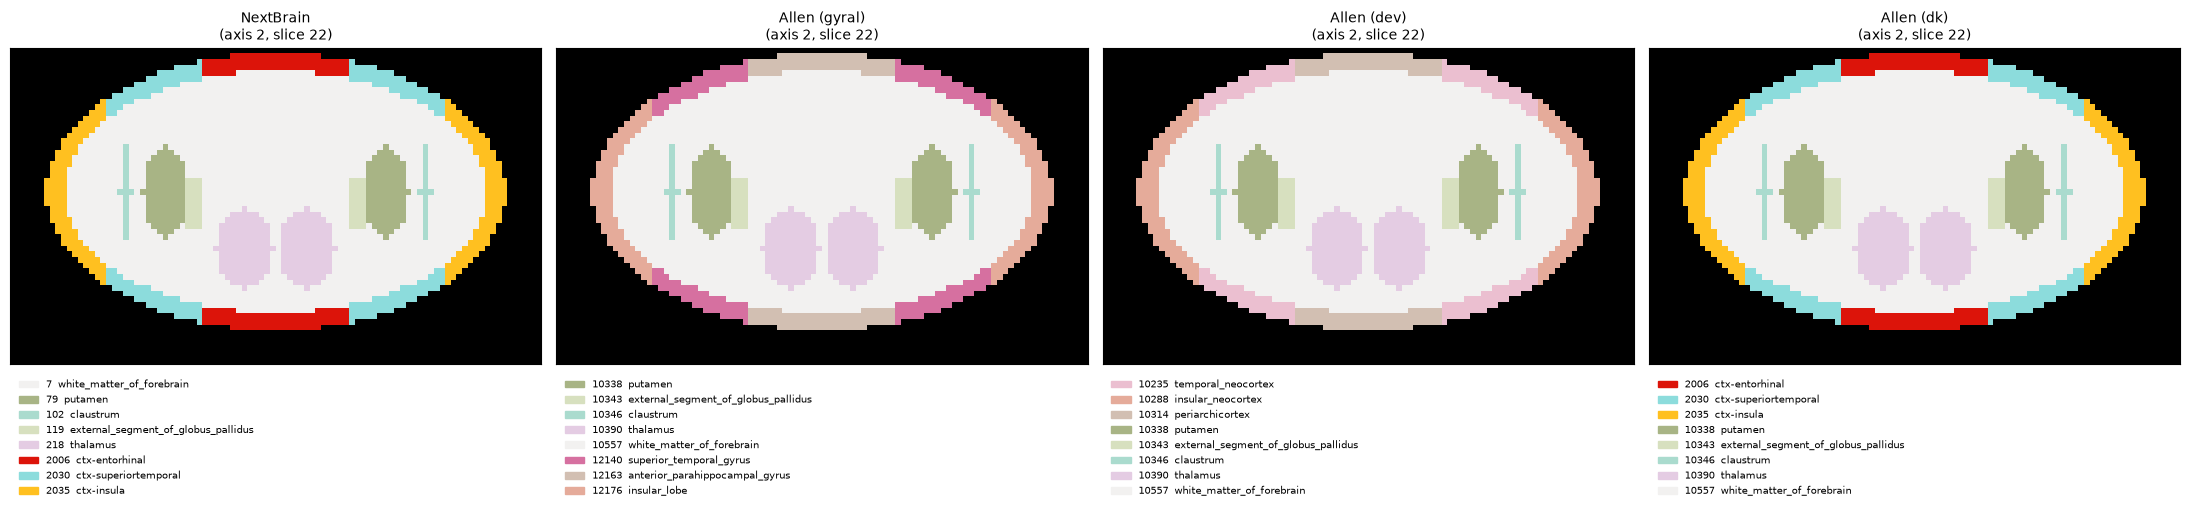

In [12]:
from nextbrain_utils.io import load_lut as _ll
allen_rows = allen_lut() + [(int(r["ID"]), r["NAME"].decode(), int(r["R"]), int(r["G"]), int(r["B"]), 0)
                            for r in nxb_lut if r["ID"] >= 2000]      # DK rows added by hand (see NB 02)
H.show_seg([combined, a_gyr, a_dev, a_dk], [nxb_lut, allen_rows, allen_rows, allen_rows], axis=2, index=22,
           titles=["NextBrain", "Allen (gyral)", "Allen (dev)", "Allen (dk)"], figsize=(22, 7))

Allen colours are shared within families (all frontal gyri look similar, all
basal ganglia are bluish). That is why some neighbouring labels are hard to
tell apart here.

### ⚠️ Issue 11 again: `int16` overflow of label 594

In [13]:
toy = nib.Nifti1Image(np.array([[[594, 79]]], dtype=np.int16), np.eye(4))
with H.patched_nextbrain_lut():
    print("gyral        :", np.asarray(TA.to_allen(toy, "gyral").dataobj).ravel())
    print("gyral + s16  :", np.asarray(TA.to_allen(toy, "gyral", compat16bits=True).dataobj).ravel(),
          " <- 594 became a negative label")

gyral        : [267498983     10338]
gyral + s16  : [-18969  10338]  <- 594 became a negative label


### ⚠️ Issue 4: array inputs

In [14]:
try:
    TA.to_allen(np.asarray(combined.dataobj), "dk")
except TypeError as e:
    print("TypeError:", e)
# Workaround: use the mapping directly - this is all to_allen does internally
arr_out = TA.get_nextbrain2allen_map("dk")[np.asarray(combined.dataobj)]
print("manual mapping:", arr_out.shape, arr_out.dtype)

TypeError: Nifti1Pair.__init__() missing 1 required positional argument: 'affine'
manual mapping: (94, 56, 48) int32


### The unused `_fscortex_to_allen_guide`

This function is a third DK table, written for the *adult guide* ontology
(`AllenBrainOntology.json`). Nothing calls it. It looks like a leftover from
an earlier version.

Next: **05 · Simplifying an Allen map**.